# Kernel PCA — Grid Search for gamma and kernel

In [4]:
from sklearn.datasets import make_moons
from sklearn.decomposition import KernelPCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

In [5]:
# Dataset
X, y = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

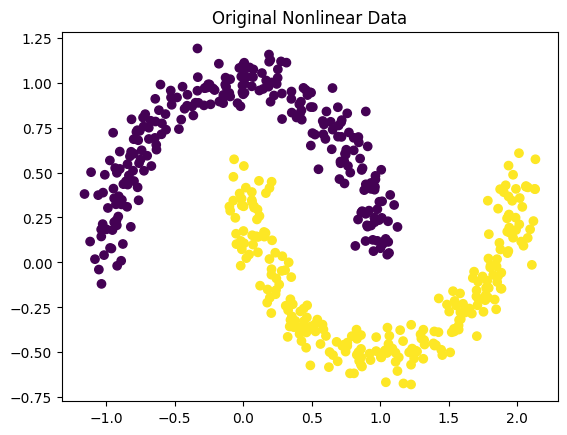

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Original Nonlinear Data")
plt.show()

In [7]:
# Step 1: Create a pipeline
pipeline = Pipeline([
    ("kpca", KernelPCA(n_components=1)),
    ("classifier", LogisticRegression())
])

In [9]:
# Step 2: Values we want GridSearchCV to try
param_grid = {
    "kpca__kernel": ["rbf", "sigmoid", "poly"],
    "kpca__gamma": [0.1, 1, 5, 10, 20]
}

In [10]:
# Step 3: Create Grid Search
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring="accuracy"
)

In [11]:
# Step 4: Train
grid_search.fit(X, y)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('kpca', KernelPCA(n_components=1)),
                                       ('classifier', LogisticRegression())]),
             param_grid={'kpca__gamma': [0.1, 1, 5, 10, 20],
                         'kpca__kernel': ['rbf', 'sigmoid', 'poly']},
             scoring='accuracy')

In [12]:
results = grid_search.cv_results_

for params, score in zip(
    results["params"],
    results["mean_test_score"]
):
    print(
        "Kernel:", params["kpca__kernel"],
        "| Gamma:", params["kpca__gamma"],
        "| Accuracy:", round(score, 3)
    )

Kernel: rbf | Gamma: 0.1 | Accuracy: 0.742
Kernel: sigmoid | Gamma: 0.1 | Accuracy: 0.74
Kernel: poly | Gamma: 0.1 | Accuracy: 0.726
Kernel: rbf | Gamma: 1 | Accuracy: 0.796
Kernel: sigmoid | Gamma: 1 | Accuracy: 0.752
Kernel: poly | Gamma: 1 | Accuracy: 0.666
Kernel: rbf | Gamma: 5 | Accuracy: 0.798
Kernel: sigmoid | Gamma: 5 | Accuracy: 0.768
Kernel: poly | Gamma: 5 | Accuracy: 0.672
Kernel: rbf | Gamma: 10 | Accuracy: 0.852
Kernel: sigmoid | Gamma: 10 | Accuracy: 0.77
Kernel: poly | Gamma: 10 | Accuracy: 0.674
Kernel: rbf | Gamma: 20 | Accuracy: 0.732
Kernel: sigmoid | Gamma: 20 | Accuracy: 0.776
Kernel: poly | Gamma: 20 | Accuracy: 0.674


In [13]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")
print(grid_search.best_score_)

Best parameters:
{'kpca__gamma': 10, 'kpca__kernel': 'rbf'}

Best cross-validation accuracy:
0.8520909987254407
